# 04 — Phase-Timing Experiment

This independent experiment separates iterative PageRank time into local computation, `MPI_Allreduce`, `MPI_Allgatherv`, and unclassified loop overhead. It uses representative strong-scaling points without replacing the original scaling measurements.

In [1]:
from pathlib import Path
import os
ROOT = Path.cwd().resolve()
if not (ROOT / 'Makefile').exists(): ROOT = ROOT.parent
assert (ROOT / 'Makefile').exists(), 'Start Jupyter from the project directory or its notebook subdirectory'
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = ROOT / 'results/vanda/phase/raw'
FIGURES = ROOT / 'results/vanda/phase/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATASET_ORDER = ['web-Google', 'web-BerkStan', 'enwiki-2013', 'uk-2002']
CPU_ORDER = [4, 32, 64, 128]
IMPLEMENTATION_ORDER = ['MPI only', 'MPI+OpenMP']
PHASES = ['compute_mean_seconds', 'allreduce_mean_seconds',
          'allgatherv_mean_seconds', 'other_mean_seconds']
PHASE_LABELS = ['Local compute', 'Allreduce', 'Allgatherv', 'Other']
PHASE_COLORS = ['#4C78A8', '#F58518', '#E45756', '#BAB0AC']

## 1. Experimental Design

Each configuration uses one warm-up and five measured runs. The instrumented program performs no additional per-iteration synchronization; phase statistics are reduced only after convergence.

| Total CPUs | Nodes | MPI only | MPI+OpenMP |
|---:|---:|---:|---:|
| 4 | 1 | 4×1 | 2×2 |
| 32 | 1 | 32×1 | 4×8 |
| 64 | 2 | 64×1 | 8×8 |
| 128 | 4 | 128×1 | 16×8 |

Phase shares use the mean elapsed time across ranks. Maxima from different phases are reported separately and are never added together.

## 2. Load and Validate Results

In [2]:
files = sorted(RAW.glob('*.csv'))
if not files:
    raise FileNotFoundError('Phase-timing CSV files are missing; run scripts/vanda/fetch_vanda_phase.sh after completion.')
runs = pd.concat((pd.read_csv(p).assign(source_file=p.name) for p in files), ignore_index=True)
parts = runs['run_id'].str.extract(r'^phase-(google|berkstan|enwiki|uk)-(\d+)x(\d+)-rep(\d+)$')
parts.columns = ['dataset_key', 'ranks_from_id', 'threads_from_id', 'repetition']
runs = pd.concat([runs, parts], axis=1)
for c in ['ranks_from_id', 'threads_from_id', 'repetition']: runs[c] = pd.to_numeric(runs[c])
name_map = {'google':'web-Google','berkstan':'web-BerkStan','enwiki':'enwiki-2013','uk':'uk-2002'}
runs['dataset_name'] = runs['dataset_key'].map(name_map)
runs['total_cpus'] = runs['mpi_ranks'] * runs['threads_per_rank']
runs['implementation'] = np.where(runs['threads_per_rank'].eq(1), 'MPI only', 'MPI+OpenMP')
runs['config'] = runs['mpi_ranks'].astype(str) + 'x' + runs['threads_per_rank'].astype(str)

expected = pd.MultiIndex.from_product([DATASET_ORDER, CPU_ORDER, IMPLEMENTATION_ORDER],
    names=['dataset_name','total_cpus','implementation']).to_frame(index=False)
counts = runs.groupby(['dataset_name','total_cpus','implementation']).size().rename('measured_runs').reset_index()
completion = expected.merge(counts, how='left')
completion['measured_runs'] = completion['measured_runs'].fillna(0).astype(int)
checks = pd.Series({
    'rows': len(runs), 'expected_rows': 160,
    'complete_configurations': completion['measured_runs'].eq(5).all(),
    'all_ids_parsed': parts.notna().all(axis=None),
    'all_converged': runs['converged'].eq(1).all(),
    'max_residual': runs['residual'].max(),
    'max_rank_sum_error': runs['rank_sum_error'].max(),
})
display(checks.to_frame('value')); display(completion)
assert len(runs) == 160
assert checks['complete_configurations'] and checks['all_ids_parsed'] and checks['all_converged']
assert checks['max_rank_sum_error'] < 1e-9

,value
rows,160
expected_rows,160
complete_configurations,True
all_ids_parsed,True
all_converged,True
max_residual,0.0
max_rank_sum_error,0.0


,dataset_name,total_cpus,implementation,measured_runs
0,web-Google,4,MPI only,5
1,web-Google,4,MPI+OpenMP,5
2,web-Google,32,MPI only,5
3,web-Google,32,MPI+OpenMP,5
4,web-Google,64,MPI only,5
5,web-Google,64,MPI+OpenMP,5
6,web-Google,128,MPI only,5
7,web-Google,128,MPI+OpenMP,5
8,web-BerkStan,4,MPI only,5
9,web-BerkStan,4,MPI+OpenMP,5


## 3. Median Phase Summary

In [3]:
runs['other_mean_seconds'] = (runs['solve_mean_seconds'] - runs[
    ['compute_mean_seconds', 'allreduce_mean_seconds', 'allgatherv_mean_seconds']
].sum(axis=1)).clip(lower=0)
for phase in PHASES:
    runs[phase.replace('_seconds', '_share')] = runs[phase] / runs['solve_mean_seconds']
runs['communication_share_run'] = (
    runs['allreduce_mean_seconds'] + runs['allgatherv_mean_seconds']
) / runs['solve_mean_seconds']

summary = (runs.groupby(['dataset_name','total_cpus','implementation','config'])
    .agg(runs=('solve_seconds','size'), median_s=('solve_seconds','median'),
         solve_mean_s=('solve_mean_seconds','median'),
         compute_mean_seconds=('compute_mean_seconds','median'),
         allreduce_mean_seconds=('allreduce_mean_seconds','median'),
         allgatherv_mean_seconds=('allgatherv_mean_seconds','median'),
         other_mean_seconds=('other_mean_seconds','median'),
         compute_mean_share=('compute_mean_share','median'),
         allreduce_mean_share=('allreduce_mean_share','median'),
         allgatherv_mean_share=('allgatherv_mean_share','median'),
         other_mean_share=('other_mean_share','median'),
         communication_share=('communication_share_run','median'),
         compute_max_seconds=('compute_max_seconds','median'),
         allreduce_max_seconds=('allreduce_max_seconds','median'),
         allgatherv_max_seconds=('allgatherv_max_seconds','median'),
         iterations=('iterations','median'))
    .reset_index())
display(summary.sort_values(['dataset_name','total_cpus','implementation']))

,dataset_name,total_cpus,implementation,config,runs,median_s,solve_mean_s,compute_mean_seconds,allreduce_mean_seconds,allgatherv_mean_seconds,other_mean_seconds,compute_mean_share,allreduce_mean_share,allgatherv_mean_share,other_mean_share,communication_share,compute_max_seconds,allreduce_max_seconds,allgatherv_max_seconds,iterations
0,enwiki-2013,4,MPI only,4x1,5,15.360178,15.360128,11.758380,2.710669,0.894940,0.000146,0.765525,0.176724,0.058213,0.000010,0.234465,14.456481,4.352752,0.899164,95.0
1,enwiki-2013,4,MPI+OpenMP,2x2,5,14.815731,14.815713,12.387359,1.881163,0.553397,0.000147,0.835887,0.126747,0.037358,0.000010,0.164103,14.259855,3.756941,0.553499,95.0
2,enwiki-2013,32,MPI only,32x1,5,4.072397,4.072209,1.579484,1.247347,1.242569,0.000098,0.387666,0.305806,0.305406,0.000024,0.612309,2.783942,1.878027,1.256089,95.0
3,enwiki-2013,32,MPI+OpenMP,4x8,5,3.150315,3.150065,1.963782,0.455774,0.729150,0.000095,0.623700,0.144364,0.231471,0.000030,0.376270,2.345279,0.846979,0.765812,95.0
4,enwiki-2013,64,MPI only,64x1,5,4.166684,4.162288,0.781224,1.573365,1.807583,0.000084,0.187699,0.378005,0.434276,0.000020,0.812281,2.068059,2.017301,1.996173,95.0
5,enwiki-2013,64,MPI+OpenMP,8x8,5,3.651980,3.649834,1.221485,1.010419,1.412716,0.000099,0.335751,0.276811,0.387063,0.000027,0.664221,2.045110,1.644983,1.515675,95.0
6,enwiki-2013,128,MPI only,128x1,5,5.827596,5.809339,0.405631,2.062390,3.371661,0.000077,0.069782,0.354268,0.575192,0.000013,0.930205,1.615555,2.744303,4.144094,95.0
7,enwiki-2013,128,MPI+OpenMP,16x8,5,3.086845,3.085442,0.747298,1.145906,1.198952,0.000085,0.240727,0.371391,0.388940,0.000027,0.759246,1.690598,1.493801,1.351398,95.0
8,uk-2002,4,MPI only,4x1,5,31.900471,31.900223,22.225934,3.759280,5.919587,0.000218,0.696583,0.117845,0.185566,0.000007,0.303411,25.923476,6.714396,5.936323,141.0
9,uk-2002,4,MPI+OpenMP,2x2,5,29.651677,29.651646,24.123476,1.941499,3.598403,0.000219,0.813221,0.065498,0.121246,0.000007,0.186772,26.036033,3.849375,3.603122,141.0


## 4. Absolute Phase Time

Bars use rank-mean phase times so the stacked components are comparable with rank-mean solve time. The original strong-scaling notebook remains the source for uninstrumented performance conclusions.

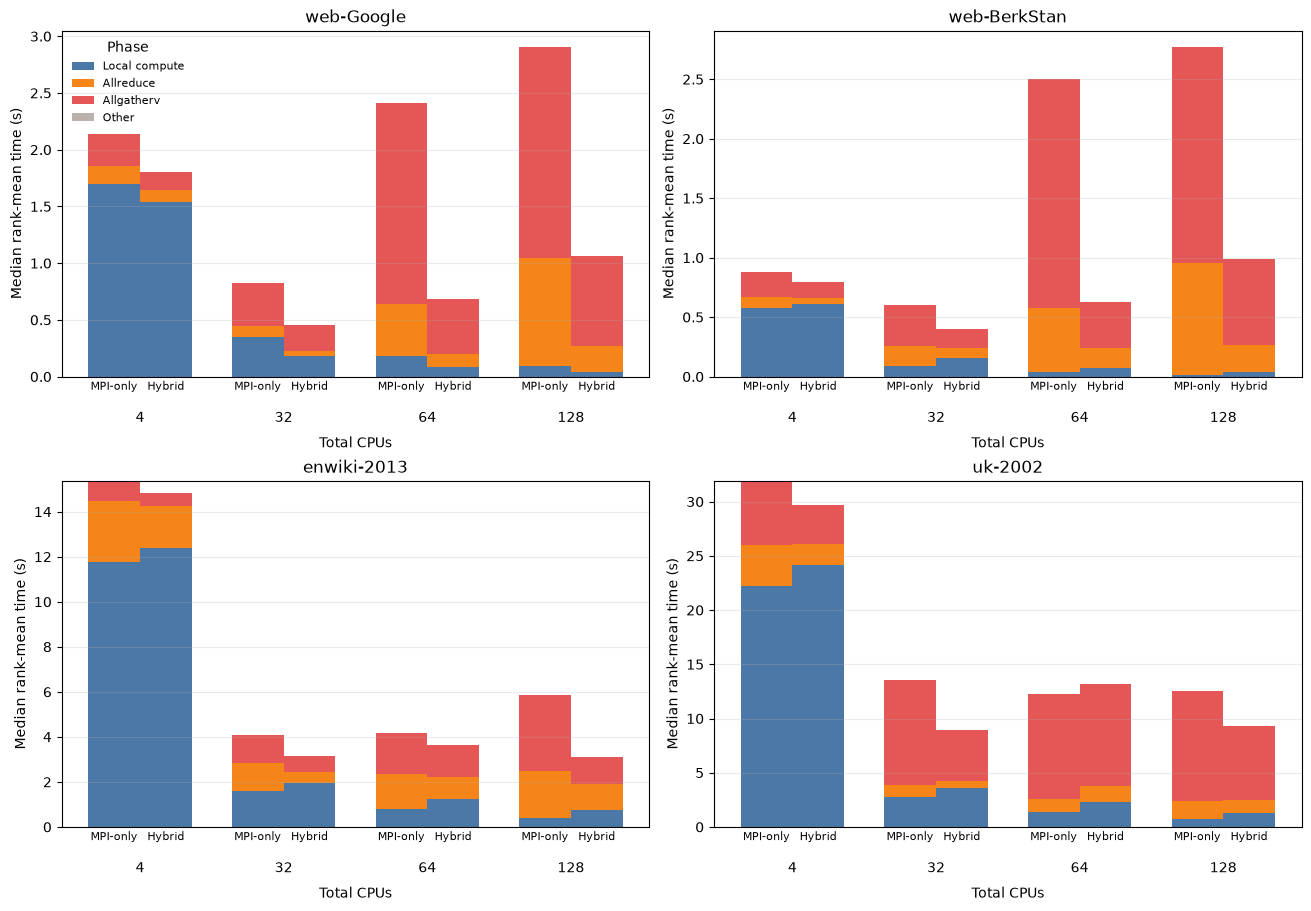

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
width = 0.36
x = np.arange(len(CPU_ORDER))
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part = summary[summary['dataset_name'].eq(dataset)]
    for j, implementation in enumerate(IMPLEMENTATION_ORDER):
        values = part[part['implementation'].eq(implementation)].set_index('total_cpus').reindex(CPU_ORDER)
        xpos = x + (j - 0.5) * width
        bottom = np.zeros(len(CPU_ORDER))
        for phase, label, color in zip(PHASES, PHASE_LABELS, PHASE_COLORS):
            height = values[phase].to_numpy()
            ax.bar(xpos, height, width, bottom=bottom, color=color,
                   label=label if j == 0 else None)
            bottom += height
    sub_positions = np.ravel(np.column_stack((x - width / 2, x + width / 2)))
    sub_labels = ['MPI-only', 'Hybrid'] * len(CPU_ORDER)
    ax.set_xticks(x, [str(cpu) for cpu in CPU_ORDER])
    ax.set_xticks(sub_positions, sub_labels, minor=True)
    ax.tick_params(axis='x', which='major', pad=25, length=0)
    ax.tick_params(axis='x', which='minor', pad=3, length=0, labelsize=8)
    ax.set_title(dataset)
    ax.set_xlabel('Total CPUs', labelpad=8)
    ax.set_ylabel('Median rank-mean time (s)')
    ax.grid(axis='y', alpha=.25)
axes[0,0].legend(frameon=False, fontsize=8, title='Phase')
fig.savefig(FIGURES/'phase_time_breakdown.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Communication Share

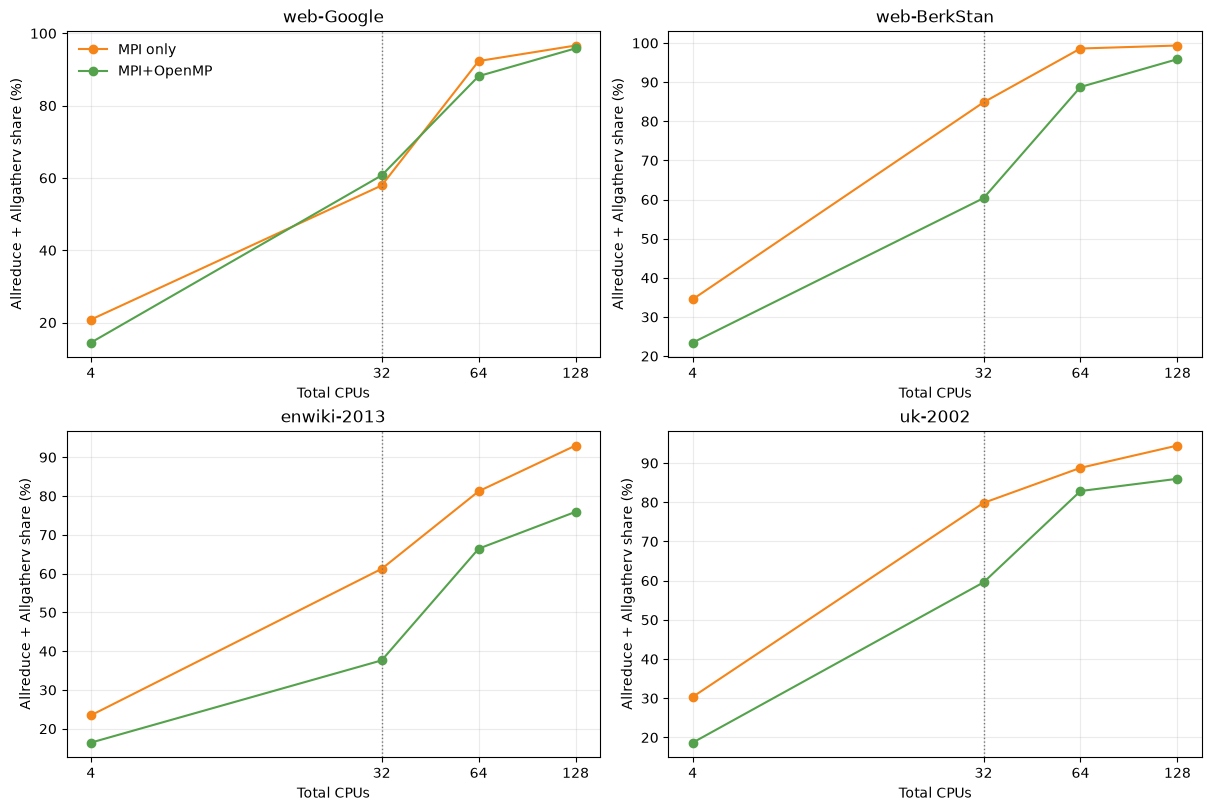

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
colors={'MPI only':'#F58518','MPI+OpenMP':'#54A24B'}
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    for implementation in IMPLEMENTATION_ORDER:
        part=(summary[(summary['dataset_name'].eq(dataset)) &
                      (summary['implementation'].eq(implementation))]
              .sort_values('total_cpus'))
        ax.plot(part['total_cpus'], 100*part['communication_share'], marker='o',
                color=colors[implementation], label=implementation)
    ax.axvline(32, color='#777777', linestyle=':', linewidth=1)
    ax.set_xscale('log',base=2); ax.set_xticks(CPU_ORDER,CPU_ORDER)
    ax.set_title(dataset); ax.set_xlabel('Total CPUs')
    ax.set_ylabel('Allreduce + Allgatherv share (%)'); ax.grid(alpha=.25)
axes[0,0].legend(frameon=False)
fig.savefig(FIGURES/'phase_communication_share.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Results

- Communication becomes dominant as resources increase. From 4 to 128 CPUs, its median share rises from 20.8% to 96.6% for Google MPI, 34.5% to 99.4% for BerkStan MPI, 23.4% to 93.0% for enwiki MPI, and 30.3% to 94.5% for UK MPI.
- Hybrid reduces communication pressure, especially for the larger graphs. At 128 CPUs the communication share is 75.9% for enwiki hybrid and 86.0% for UK hybrid, versus 93.0% and 94.5% for MPI-only.
- `Allgatherv` is the largest 128-CPU component in most configurations: 63.5%–80.4% for MPI-only and 38.9%–75.3% for hybrid. This directly supports the earlier conclusion that full score-vector synchronization limits scaling.
- enwiki hybrid retains the largest useful compute share at 128 CPUs (24.1%); smaller graphs spend almost all time in collectives. More CPUs therefore cannot improve runtime once communication dominates.
- Phase shares are computed per measured run and then summarized by the median. Rank-max phase values remain available in the table but are not added together.

## 7. Reproduce

On Vanda, enter the extracted project root (the directory containing `Makefile`) and run:

```bash
test -f Makefile && test -d scripts/vanda
bash scripts/vanda/submit_vanda_phase.sh "$PWD"
```

From a local copy of the project, fetch completed results with your own Vanda login and the project path relative to your remote home directory, then run all cells:

```bash
bash scripts/vanda/fetch_vanda_phase.sh <nusnet-id>@vanda.nus.edu.sg DSA5208_Project3
```